In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Readme.txt
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Info/CAM_test.txt
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Info/CAM_train.txt
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Info/NonCAM_test.txt
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Info/NonCAM_train.txt
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Info/Statistics-CAM.xlsx
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/CAM-NonCAM_Instance_Test.txt
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/CAM_Instance_Test.json
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/GT_Edge/COD10K-CAM-1-Aquatic-1-BatFish-2.png
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/GT_Edge/COD10K-CAM-1-Aquatic-1-BatFish-4.png
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/GT_Edge/COD10K-CAM-1-Aquatic-1-BatFish-5.png
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/GT_Edge/COD10K-CAM-1-Aquatic-1-BatFish-6.png
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/GT_Edg

# **ENV and Data Verification**

In [2]:
# ============================================================
# COD10K RESNET34 U-NET RETRAINING
# STEP 1: ENVIRONMENT AND DATASET VERIFICATION
# ============================================================

import os
import sys
import torch
import torchvision
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 60)
print("ENVIRONMENT INFORMATION")
print("=" * 60)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)

print("\nCUDA AVAILABLE:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

print("\n" + "=" * 60)
print("KAGGLE INPUT DATASETS")
print("=" * 60)

INPUT_DIR = Path("/kaggle/input")

for path in INPUT_DIR.iterdir():
    print("\n", path)

    if path.is_dir():
        for child in list(path.iterdir())[:10]:
            print("   ", child)

print("\n" + "=" * 60)
print("WORKING DIRECTORY")
print("=" * 60)

PROJECT_DIR = Path("/kaggle/working/COD10K-ResNet34UNet-Retraining")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

for folder in ["models", "results", "checkpoints"]:
    (PROJECT_DIR / folder).mkdir(exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Project directory exists:", PROJECT_DIR.exists())

ENVIRONMENT INFORMATION
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
NumPy: 2.1.3

CUDA AVAILABLE: True
GPU: Tesla T4
GPU Memory: 14.56 GB

KAGGLE INPUT DATASETS

 /kaggle/input/datasets
    /kaggle/input/datasets/mrcaro

WORKING DIRECTORY
Project directory: /kaggle/working/COD10K-ResNet34UNet-Retraining
Project directory exists: True


In [3]:
# ============================================================
# STEP 2: FIND COD10K DATASET AND PROJECT FILES
# ============================================================

from pathlib import Path

ROOT = Path("/kaggle/input/datasets/mrcaro")

print("=" * 65)
print("SEARCHING FOR DATASET FOLDERS AND PROJECT FILES")
print("=" * 65)

for path in ROOT.rglob("*"):
    if path.is_dir() and path.name in ["Train", "Test", "Image", "GT_Object", "models"]:
        print("FOLDER:", path)

    elif path.is_file() and path.name in [
        "dataset.py",
        "unet.py",
        "losses.py",
        "requirements.txt"
    ]:
        print("FILE:", path)

print("\n" + "=" * 65)
print("VERIFYING COD10K IMAGE AND MASK FOLDERS")
print("=" * 65)

for split in ["Train", "Test"]:
    image_folders = list(ROOT.rglob(f"{split}/Image"))
    mask_folders = list(ROOT.rglob(f"{split}/GT_Object"))

    print(f"\n{split}:")
    print("Image folders:", image_folders)
    print("Mask folders:", mask_folders)

    for folder in image_folders + mask_folders:
        files = [f for f in folder.iterdir() if f.is_file()]
        print(f"{folder}: {len(files)} files")

SEARCHING FOR DATASET FOLDERS AND PROJECT FILES
FOLDER: /kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test
FOLDER: /kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Train
FOLDER: /kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/GT_Object
FOLDER: /kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/Image
FOLDER: /kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Train/GT_Object
FOLDER: /kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Train/Image

VERIFYING COD10K IMAGE AND MASK FOLDERS

Train:
Image folders: [PosixPath('/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Train/Image')]
Mask folders: [PosixPath('/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Train/GT_Object')]
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Train/Image: 6000 files
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Train/GT_Object: 6000 files

Test:
Image folders: [PosixPath('/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/Image')]
Mask folders: [PosixPath('/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/GT_Objec

In [4]:
# ============================================================
# STEP 3: VERIFY COD10K DATASET
# ============================================================

from pathlib import Path

DATASET_DIR = Path(
    "/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3"
)

for split in ["Train", "Test"]:

    image_dir = DATASET_DIR / split / "Image"
    mask_dir = DATASET_DIR / split / "GT_Object"

    images = sorted(image_dir.glob("*.jpg"))
    masks = sorted(mask_dir.glob("*.png"))

    image_stems = {f.stem for f in images}
    mask_stems = {f.stem for f in masks}

    print(f"\n{split.upper()} DATASET")
    print("-" * 45)
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Matching pairs:", len(image_stems & mask_stems))
    print("Images without masks:", len(image_stems - mask_stems))
    print("Masks without images:", len(mask_stems - image_stems))

print("\nDATASET VERIFICATION COMPLETE")


TRAIN DATASET
---------------------------------------------
Images: 6000
Masks: 6000
Matching pairs: 6000
Images without masks: 0
Masks without images: 0

TEST DATASET
---------------------------------------------
Images: 4000
Masks: 4000
Matching pairs: 4000
Images without masks: 0
Masks without images: 0

DATASET VERIFICATION COMPLETE


# **Normalized Dataset**

In [5]:
# ============================================================
# STEP 4: COD10K DATASET AND IMAGENET NORMALIZATION
# ============================================================

import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from pathlib import Path

IMAGE_SIZE = 352
BATCH_SIZE = 8
RANDOM_SEED = 42

# ImageNet normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

mask_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=transforms.InterpolationMode.NEAREST
    ),
    transforms.ToTensor()
])


class COD10KDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)

        self.images = sorted(self.image_dir.glob("*.jpg"))

        self.pairs = []

        for image_path in self.images:
            mask_path = self.mask_dir / (image_path.stem + ".png")

            if mask_path.exists():
                self.pairs.append((image_path, mask_path))

        if not self.pairs:
            raise RuntimeError("No matching image-mask pairs found.")

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):

        image_path, mask_path = self.pairs[idx]

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = image_transform(image)
        mask = mask_transform(mask)

        mask = (mask > 0.5).float()

        return image, mask


# Load training dataset
full_train_dataset = COD10KDataset(
    DATASET_DIR / "Train" / "Image",
    DATASET_DIR / "Train" / "GT_Object"
)

# Reproducible 90/10 split
generator = torch.Generator().manual_seed(RANDOM_SEED)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [5400, 600],
    generator=generator
)

# Loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

print("DATASET PIPELINE CREATED")
print("=" * 50)
print("Total training dataset:", len(full_train_dataset))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

DATASET PIPELINE CREATED
Total training dataset: 6000
Training samples: 5400
Validation samples: 600
Training batches: 675
Validation batches: 75


In [6]:
# ============================================================
# STEP 5: VERIFY NORMALIZED BATCH
# ============================================================

images, masks = next(iter(train_loader))

print("IMAGE BATCH")
print("Shape:", images.shape)
print("Dtype:", images.dtype)
print("Min:", images.min().item())
print("Max:", images.max().item())
print("Mean:", images.mean().item())
print("Std:", images.std().item())

print("\nMASK BATCH")
print("Shape:", masks.shape)
print("Dtype:", masks.dtype)
print("Unique values:", torch.unique(masks))
print("Foreground percentage:", masks.mean().item() * 100)

assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert masks.shape == (BATCH_SIZE, 1, IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(images).all()
assert torch.isfinite(masks).all()
assert set(torch.unique(masks).tolist()).issubset({0.0, 1.0})

print("\nALL DATA PIPELINE CHECKS PASSED")

IMAGE BATCH
Shape: torch.Size([8, 3, 352, 352])
Dtype: torch.float32
Min: -2.1179039478302
Max: 2.640000104904175
Mean: -0.07762321829795837
Std: 0.9567502737045288

MASK BATCH
Shape: torch.Size([8, 1, 352, 352])
Dtype: torch.float32
Unique values: tensor([0., 1.])
Foreground percentage: 1.2181810103356838

ALL DATA PIPELINE CHECKS PASSED


# **ResNet34 U-Net**

In [7]:
# ============================================================
# STEP 6: RESNET34 PRETRAINED ENCODER CHECK
# ============================================================

import torch
import torchvision
from torchvision.models import resnet34, ResNet34_Weights

print("Loading pretrained ResNet34 weights...")

encoder = resnet34(weights=ResNet34_Weights.DEFAULT)

print("\nRESNET34 INITIALIZED")
print("=" * 50)
print("Architecture:", type(encoder).__name__)
print("Pretrained weights:", ResNet34_Weights.DEFAULT)
print("First convolution:", encoder.conv1)
print("Final classification layer:", encoder.fc)

print("\nParameter count:",
      sum(p.numel() for p in encoder.parameters()))

del encoder

Loading pretrained ResNet34 weights...
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 221MB/s]



RESNET34 INITIALIZED
Architecture: ResNet
Pretrained weights: ResNet34_Weights.IMAGENET1K_V1
First convolution: Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
Final classification layer: Linear(in_features=512, out_features=1000, bias=True)

Parameter count: 21797672


In [8]:
# ============================================================
# STEP 7: RESNET34 U-NET MODEL
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet34, ResNet34_Weights


class DecoderBlock(nn.Module):

    def __init__(self, in_channels, skip_channels, out_channels):

        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels + skip_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x, skip):

        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)

        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))

        return x


class ResNet34UNet(nn.Module):

    def __init__(self, pretrained=True):

        super().__init__()

        weights = (
            ResNet34_Weights.DEFAULT if pretrained else None
        )

        backbone = resnet34(weights=weights)

        # Encoder
        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        # Decoder
        self.center = DecoderBlock(512, 256, 256)
        self.decoder3 = DecoderBlock(256, 128, 128)
        self.decoder2 = DecoderBlock(128, 64, 64)
        self.decoder1 = DecoderBlock(64, 64, 64)

        self.final_upsample = nn.Sequential(
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, kernel_size=1)
        )

    def forward(self, x):

        input_size = x.shape[2:]

        # Encoder
        x0 = self.relu(self.bn1(self.conv1(x)))
        x1 = self.layer1(self.maxpool(x0))
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)

        # Decoder
        d4 = self.center(x4, x3)
        d3 = self.decoder3(d4, x2)
        d2 = self.decoder2(d3, x1)
        d1 = self.decoder1(d2, x0)

        output = F.interpolate(
            d1,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        return self.final_upsample(output)


# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ResNet34UNet(pretrained=True).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("MODEL INITIALIZED")
print("=" * 50)
print("Architecture: ResNet34 U-Net")
print("Device:", device)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

MODEL INITIALIZED
Architecture: ResNet34 U-Net
Device: cuda
Total parameters: 24,512,449
Trainable parameters: 24,512,449


In [9]:
# ============================================================
# STEP 8: MODEL FORWARD PASS TEST
# ============================================================

model.eval()

sample_images, sample_masks = next(iter(train_loader))

sample_images = sample_images.to(device)
sample_masks = sample_masks.to(device)

with torch.no_grad():

    predictions = model(sample_images)

print("INPUT SHAPE:", sample_images.shape)
print("MASK SHAPE:", sample_masks.shape)
print("OUTPUT SHAPE:", predictions.shape)
print("OUTPUT DTYPE:", predictions.dtype)
print("OUTPUT DEVICE:", predictions.device)

assert predictions.shape == sample_masks.shape

print("\nMODEL FORWARD PASS SUCCESSFUL")

INPUT SHAPE: torch.Size([8, 3, 352, 352])
MASK SHAPE: torch.Size([8, 1, 352, 352])
OUTPUT SHAPE: torch.Size([8, 1, 352, 352])
OUTPUT DTYPE: torch.float32
OUTPUT DEVICE: cuda:0

MODEL FORWARD PASS SUCCESSFUL


# **Combined BCE + Dice Loss**

In [10]:
# ============================================================
# STEP 9: COMBINED BCE + DICE LOSS
# ============================================================

import torch
import torch.nn as nn


class CombinedLoss(nn.Module):

    def __init__(self, bce_weight=0.5, dice_weight=0.5):
        super().__init__()

        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, predictions, targets):

        bce_loss = self.bce(predictions, targets)

        probabilities = torch.sigmoid(predictions)

        smooth = 1.0

        intersection = (probabilities * targets).sum(
            dim=(2, 3)
        )

        denominator = (
            probabilities.sum(dim=(2, 3))
            + targets.sum(dim=(2, 3))
        )

        dice_score = (
            (2.0 * intersection + smooth)
            / (denominator + smooth)
        )

        dice_loss = 1.0 - dice_score.mean()

        total_loss = (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )

        return total_loss


criterion = CombinedLoss(
    bce_weight=0.5,
    dice_weight=0.5
)

# Test loss
model.train()

sample_images, sample_masks = next(iter(train_loader))

sample_images = sample_images.to(device)
sample_masks = sample_masks.to(device)

predictions = model(sample_images)
loss = criterion(predictions, sample_masks)

print("LOSS FUNCTION TEST")
print("=" * 50)
print("BCE + Dice combined loss:", loss.item())

assert torch.isfinite(loss)

print("\nLOSS FUNCTION TEST PASSED")

LOSS FUNCTION TEST
BCE + Dice combined loss: 0.811370849609375

LOSS FUNCTION TEST PASSED


# **Optimizer**

In [11]:
# ============================================================
# STEP 10: OPTIMIZER CONFIGURATION
# ============================================================

import torch.optim as optim

encoder_parameters = (
    list(model.conv1.parameters())
    + list(model.bn1.parameters())
    + list(model.layer1.parameters())
    + list(model.layer2.parameters())
    + list(model.layer3.parameters())
    + list(model.layer4.parameters())
)

decoder_parameters = (
    list(model.center.parameters())
    + list(model.decoder3.parameters())
    + list(model.decoder2.parameters())
    + list(model.decoder1.parameters())
    + list(model.final_upsample.parameters())
)

optimizer = optim.AdamW(
    [
        {
            "params": encoder_parameters,
            "lr": 1e-4
        },
        {
            "params": decoder_parameters,
            "lr": 1e-3
        }
    ],
    weight_decay=1e-4
)

print("OPTIMIZER CONFIGURATION")
print("=" * 50)
print("Optimizer: AdamW")
print("Encoder LR: 0.0001")
print("Decoder LR: 0.001")
print("Weight decay: 0.0001")
print("Encoder parameter tensors:", len(encoder_parameters))
print("Decoder parameter tensors:", len(decoder_parameters))

OPTIMIZER CONFIGURATION
Optimizer: AdamW
Encoder LR: 0.0001
Decoder LR: 0.001
Weight decay: 0.0001
Encoder parameter tensors: 108
Decoder parameter tensors: 30


# **Training**

In [12]:
# ============================================================
# STEP 11: TRAINING CONFIGURATION + RESUME SUPPORT
# ============================================================

import os
import gc
import torch
import pandas as pd
from pathlib import Path

EPOCHS = 20

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [CHECKPOINT_DIR, MODEL_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_model.pth"
LATEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "latest_checkpoint.pth"

HISTORY_PATH = RESULTS_DIR / "training_history.csv"

best_val_loss = float("inf")
start_epoch = 0

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": []
}

# ------------------------------------------------------------
# AUTOMATIC CHECKPOINT RECOVERY
# ------------------------------------------------------------

if LATEST_CHECKPOINT_PATH.exists():

    print("RECOVERY CHECKPOINT FOUND")
    print("Loading previous training progress...")

    checkpoint = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    if "scaler_state_dict" in checkpoint:
        scaler.load_state_dict(
            checkpoint["scaler_state_dict"]
        )

    start_epoch = checkpoint["epoch"]

    best_val_loss = checkpoint["best_val_loss"]

    history = checkpoint["history"]

    print("\nTRAINING RESTORED SUCCESSFULLY")
    print("Last completed epoch:", start_epoch)
    print("Next epoch:", start_epoch + 1)
    print("Best validation loss:", best_val_loss)

else:

    print("NO PREVIOUS CHECKPOINT FOUND")
    print("Starting fresh training from epoch 1.")

print("\nTRAINING CONFIGURATION")
print("=" * 50)
print("Total epochs:", EPOCHS)
print("Starting epoch:", start_epoch + 1)
print("Mixed precision:", scaler.is_enabled())
print("Recovery enabled: True")

NO PREVIOUS CHECKPOINT FOUND
Starting fresh training from epoch 1.

TRAINING CONFIGURATION
Total epochs: 20
Starting epoch: 1
Mixed precision: True
Recovery enabled: True


In [15]:

# ============================================================
# STEP 12: REAL-TIME TRAINING WITH ACCURACY + CRASH RECOVERY
# ============================================================

import time
import gc
import os
import pandas as pd
import torch
from tqdm.auto import tqdm


# ------------------------------------------------------------
# ATOMIC CHECKPOINT SAVING
# ------------------------------------------------------------

def atomic_save(data, destination):

    temporary_path = str(destination) + ".tmp"

    torch.save(data, temporary_path)

    os.replace(temporary_path, destination)


# ------------------------------------------------------------
# ENSURE HISTORY SUPPORTS ACCURACY
# ------------------------------------------------------------

history.setdefault("train_accuracy", [])
history.setdefault("val_accuracy", [])


# ------------------------------------------------------------
# TRAINING LOOP
# ------------------------------------------------------------

for epoch in range(start_epoch, EPOCHS):

    epoch_start = time.time()

    # ==================== TRAINING ====================

    model.train()

    train_loss_total = 0.0
    train_correct_pixels = 0
    train_total_pixels = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} - Training",
        leave=True
    )

    for batch_idx, (images, masks) in enumerate(train_bar):

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)
            loss = criterion(outputs, masks)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        train_loss_total += loss.item()

        # Pixel accuracy at threshold 0.5
        predictions = torch.sigmoid(outputs) > 0.5
        targets = masks > 0.5

        train_correct_pixels += (
            predictions == targets
        ).sum().item()

        train_total_pixels += targets.numel()

        running_train_loss = (
            train_loss_total / (batch_idx + 1)
        )

        running_train_accuracy = (
            100.0 * train_correct_pixels / train_total_pixels
        )

        # REAL-TIME PROGRESS
        train_bar.set_postfix(
            loss=f"{running_train_loss:.4f}",
            pixel_acc=f"{running_train_accuracy:.2f}%"
        )

    train_loss = train_loss_total / len(train_loader)

    train_accuracy = (
        100.0 * train_correct_pixels / train_total_pixels
    )

    # ==================== VALIDATION ====================

    model.eval()

    val_loss_total = 0.0
    val_correct_pixels = 0
    val_total_pixels = 0

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} - Validation",
        leave=True
    )

    with torch.no_grad():

        for batch_idx, (images, masks) in enumerate(val_bar):

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)
                loss = criterion(outputs, masks)

            val_loss_total += loss.item()

            predictions = torch.sigmoid(outputs) > 0.5
            targets = masks > 0.5

            val_correct_pixels += (
                predictions == targets
            ).sum().item()

            val_total_pixels += targets.numel()

            running_val_loss = (
                val_loss_total / (batch_idx + 1)
            )

            running_val_accuracy = (
                100.0 * val_correct_pixels / val_total_pixels
            )

            # REAL-TIME VALIDATION PROGRESS
            val_bar.set_postfix(
                loss=f"{running_val_loss:.4f}",
                pixel_acc=f"{running_val_accuracy:.2f}%"
            )

    val_loss = val_loss_total / len(val_loader)

    val_accuracy = (
        100.0 * val_correct_pixels / val_total_pixels
    )

    # ==================== UPDATE HISTORY ====================

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    # ==================== BEST MODEL ====================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        atomic_save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "architecture": "ResNet34UNet",
                "image_size": IMAGE_SIZE,
                "normalization": "ImageNet"
            },
            BEST_MODEL_PATH
        )

        print(
            f"\nBEST MODEL UPDATED | "
            f"Validation Loss: {best_val_loss:.6f}",
            flush=True
        )

    # ==================== RECOVERY CHECKPOINT ====================

    recovery_data = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "history": history
    }

    atomic_save(
        recovery_data,
        LATEST_CHECKPOINT_PATH
    )

    # ==================== EPOCH SUMMARY ====================

    elapsed = time.time() - epoch_start

    print("\n" + "=" * 65, flush=True)
    print(f"EPOCH [{epoch+1}/{EPOCHS}] COMPLETED", flush=True)
    print(f"Training Loss:       {train_loss:.6f}", flush=True)
    print(f"Validation Loss:     {val_loss:.6f}", flush=True)
    print(f"Training Pixel Acc:  {train_accuracy:.2f}%", flush=True)
    print(f"Validation Pixel Acc:{val_accuracy:.2f}%", flush=True)
    print(f"Best Validation Loss:{best_val_loss:.6f}", flush=True)
    print(f"Epoch Time:          {elapsed/60:.2f} minutes", flush=True)
    print("=" * 65 + "\n", flush=True)

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# TRAINING COMPLETION
# ------------------------------------------------------------

print("\nTRAINING COMPLETED", flush=True)
print("Best validation loss:", best_val_loss)
print("Best model:", BEST_MODEL_PATH)
print("Recovery checkpoint:", LATEST_CHECKPOINT_PATH)
print("Training history:", HISTORY_PATH)

Epoch 1/20 - Training:   0%|          | 0/675 [00:00<?, ?it/s]

Epoch 1/20 - Validation:   0%|          | 0/75 [00:00<?, ?it/s]


BEST MODEL UPDATED | Validation Loss: 0.454839

EPOCH [1/20] COMPLETED
Training Loss:       0.453539
Validation Loss:     0.454839
Training Pixel Acc:  95.32%
Validation Pixel Acc:95.96%
Best Validation Loss:0.454839
Epoch Time:          5.74 minutes



Epoch 2/20 - Training:   0%|          | 0/675 [00:00<?, ?it/s]

Epoch 2/20 - Validation:   0%|          | 0/75 [00:00<?, ?it/s]


BEST MODEL UPDATED | Validation Loss: 0.359657

EPOCH [2/20] COMPLETED
Training Loss:       0.392999
Validation Loss:     0.359657
Training Pixel Acc:  96.33%
Validation Pixel Acc:96.33%
Best Validation Loss:0.359657
Epoch Time:          1.74 minutes



... (50 outputs left out)


EPOCH [19/20] COMPLETED
Training Loss:       0.074038
Validation Loss:     0.305354
Training Pixel Acc:  99.03%
Validation Pixel Acc:96.84%
Best Validation Loss:0.251776
Epoch Time:          1.73 minutes



Epoch 20/20 - Training:   0%|          | 0/675 [00:00<?, ?it/s]

Epoch 20/20 - Validation:   0%|          | 0/75 [00:00<?, ?it/s]


EPOCH [20/20] COMPLETED
Training Loss:       0.072893
Validation Loss:     0.307485
Training Pixel Acc:  99.04%
Validation Pixel Acc:96.83%
Best Validation Loss:0.251776
Epoch Time:          1.73 minutes


TRAINING COMPLETED
Best validation loss: 0.2517758094271024
Best model: /kaggle/working/COD10K-ResNet34UNet-Retraining/models/best_model.pth
Recovery checkpoint: /kaggle/working/COD10K-ResNet34UNet-Retraining/checkpoints/latest_checkpoint.pth
Training history: /kaggle/working/COD10K-ResNet34UNet-Retraining/results/training_history.csv


# **Training History**

In [16]:
import pandas as pd

history_df = pd.read_csv(HISTORY_PATH)

print("TRAINING HISTORY")
display(history_df)

print("\nTOTAL EPOCHS:", len(history_df))

print("\nBEST VALIDATION EPOCH:")
best_row = history_df.loc[history_df["val_loss"].idxmin()]
display(best_row)

print("\nAVAILABLE COLUMNS:")
print(history_df.columns.tolist())

TRAINING HISTORY


,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,0.453539,0.454839,95.318782,95.963008
1,2,0.392999,0.359657,96.331809,96.334181
2,3,0.255271,0.265608,96.803153,95.709973
3,4,0.213617,0.288045,97.282315,96.692225
4,5,0.182873,0.303272,97.618963,96.603561
5,6,0.161826,0.268821,97.891108,96.595496
6,7,0.146450,0.259025,98.112285,96.774360
7,8,0.135780,0.251776,98.258938,96.811755
8,9,0.123477,0.283044,98.392681,96.766852
9,10,0.107308,0.286360,98.577601,96.818042



TOTAL EPOCHS: 20

BEST VALIDATION EPOCH:


epoch              8.000000
train_loss         0.135780
val_loss           0.251776
train_accuracy    98.258938
val_accuracy      96.811755
Name: 7, dtype: float64


AVAILABLE COLUMNS:
['epoch', 'train_loss', 'val_loss', 'train_accuracy', 'val_accuracy']


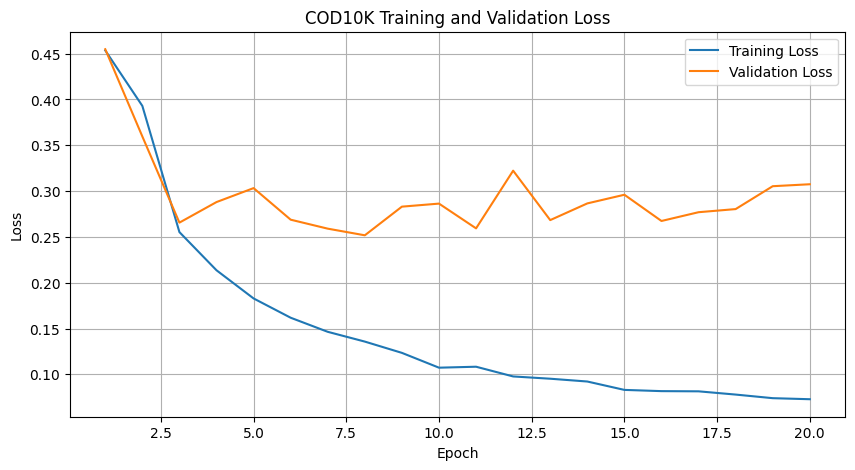

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("COD10K Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# **Load the best trained model**

In [19]:

# ============================================================
# STEP 13: LOAD BEST TRAINED MODEL
# ============================================================

import torch
from pathlib import Path

# Best checkpoint location
BEST_MODEL_PATH = PROJECT_DIR / "models" / "best_model.pth"

# Verify checkpoint exists
if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Best model checkpoint not found: {BEST_MODEL_PATH}"
    )

# Load checkpoint
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

# Restore best model weights (epoch 8)
model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

# Switch model to evaluation mode
model.eval()

# Display checkpoint information
print("BEST MODEL LOADED SUCCESSFULLY")

print("Architecture:", best_checkpoint["architecture"])
print("Best Epoch:", best_checkpoint["epoch"])
print("Best Validation Loss:", best_checkpoint["best_val_loss"])
print("Image Size:", best_checkpoint["image_size"])
print("Normalization:", best_checkpoint["normalization"])
print("Device:", device)
print("Model Parameters:", sum(p.numel() for p in model.parameters()))

print("\nModel is ready for test evaluation.")

BEST MODEL LOADED SUCCESSFULLY
Architecture: ResNet34UNet
Best Epoch: 8
Best Validation Loss: 0.2517758094271024
Image Size: 352
Normalization: ImageNet
Device: cuda
Model Parameters: 24512449

Model is ready for test evaluation.


# **Inspect the test dataset loader**

In [20]:

# ============================================================
# STEP 14: INSPECT DATASET CLASS AND TEST PATHS
# ============================================================

import inspect

print("DATASET CLASS")
print(inspect.signature(COD10KDataset))

print("\nDATASET ROOT")
print(DATASET_DIR)

print("\nTEST IMAGE DIRECTORY")
print(DATASET_DIR / "Test" / "Image")

print("\nTEST MASK DIRECTORY")
print(DATASET_DIR / "Test" / "GT_Object")

print("\nTEST IMAGE COUNT")
print(len(list((DATASET_DIR / "Test" / "Image").glob("*"))))

print("\nTEST MASK COUNT")
print(len(list((DATASET_DIR / "Test" / "GT_Object").glob("*"))))

DATASET CLASS
(image_dir, mask_dir)

DATASET ROOT
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3

TEST IMAGE DIRECTORY
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/Image

TEST MASK DIRECTORY
/kaggle/input/datasets/mrcaro/cod10k/COD10K-v3/Test/GT_Object

TEST IMAGE COUNT
4000

TEST MASK COUNT
4000


# **COD10K test DataLoader**

In [21]:

# ============================================================
# STEP 15: CREATE COD10K TEST DATASET AND DATALOADER
# ============================================================

from torch.utils.data import DataLoader

# Test directories
TEST_IMAGE_DIR = DATASET_DIR / "Test" / "Image"
TEST_MASK_DIR = DATASET_DIR / "Test" / "GT_Object"

# Create test dataset using the existing dataset class
test_dataset = COD10KDataset(
    image_dir=str(TEST_IMAGE_DIR),
    mask_dir=str(TEST_MASK_DIR)
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

# Inspect one batch
test_images, test_masks = next(iter(test_loader))

print("COD10K TEST DATALOADER")

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("Batch size:", test_loader.batch_size)

print("\nBATCH VERIFICATION")
print("Image shape:", test_images.shape)
print("Mask shape:", test_masks.shape)

print("\nIMAGE INFORMATION")
print("Data type:", test_images.dtype)
print("Minimum:", test_images.min().item())
print("Maximum:", test_images.max().item())
print("Mean:", test_images.mean().item())

print("\nMASK INFORMATION")
print("Data type:", test_masks.dtype)
print("Unique values:", torch.unique(test_masks))
print("Foreground percentage:",
      (test_masks.mean().item() * 100))

print("\nTest DataLoader is ready.")

COD10K TEST DATALOADER
Test images: 4000
Test batches: 500
Batch size: 8

BATCH VERIFICATION
Image shape: torch.Size([8, 3, 352, 352])
Mask shape: torch.Size([8, 1, 352, 352])

IMAGE INFORMATION
Data type: torch.float32
Minimum: -2.1179039478302
Maximum: 2.640000104904175
Mean: -0.17024043202400208

MASK INFORMATION
Data type: torch.float32
Unique values: tensor([0., 1.])
Foreground percentage: 19.224056601524353

Test DataLoader is ready.


# **Predictions on all 4,000 test images**

In [22]:

# ============================================================
# STEP 16: GENERATE PREDICTIONS ON ALL 4000 TEST IMAGES
# ============================================================

import numpy as np
from tqdm.auto import tqdm
import torch

model.eval()

predictions = []
ground_truths = []

with torch.no_grad():

    test_bar = tqdm(
        test_loader,
        desc="Evaluating COD10K Test Images"
    )

    for images, masks in test_bar:

        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

        # Convert logits to probabilities
        probs = torch.sigmoid(outputs.float())

        # Move predictions and masks to CPU
        predictions.extend(
            probs.cpu().numpy().astype(np.float32)
        )

        ground_truths.extend(
            masks.cpu().numpy().astype(np.float32)
        )

        test_bar.set_postfix(
            processed=len(predictions) * test_loader.batch_size
        )

# Convert to NumPy arrays
predictions = np.concatenate(predictions, axis=0)
ground_truths = np.concatenate(ground_truths, axis=0)

print("TEST INFERENCE COMPLETED")

print("Predictions shape:", predictions.shape)
print("Ground truth shape:", ground_truths.shape)

print("Prediction minimum:", predictions.min())
print("Prediction maximum:", predictions.max())
print("Prediction mean:", predictions.mean())

print("Ground truth unique values:", np.unique(ground_truths))

print("\nTotal evaluated images:", len(predictions))

Evaluating COD10K Test Images:   0%|          | 0/500 [00:00<?, ?it/s]

TEST INFERENCE COMPLETED
Predictions shape: (4000, 352, 352)
Ground truth shape: (4000, 352, 352)
Prediction minimum: 2.362419e-11
Prediction maximum: 0.99998915
Prediction mean: 0.032924365
Ground truth unique values: [0. 1.]

Total evaluated images: 4000


# **Visualize predictions**

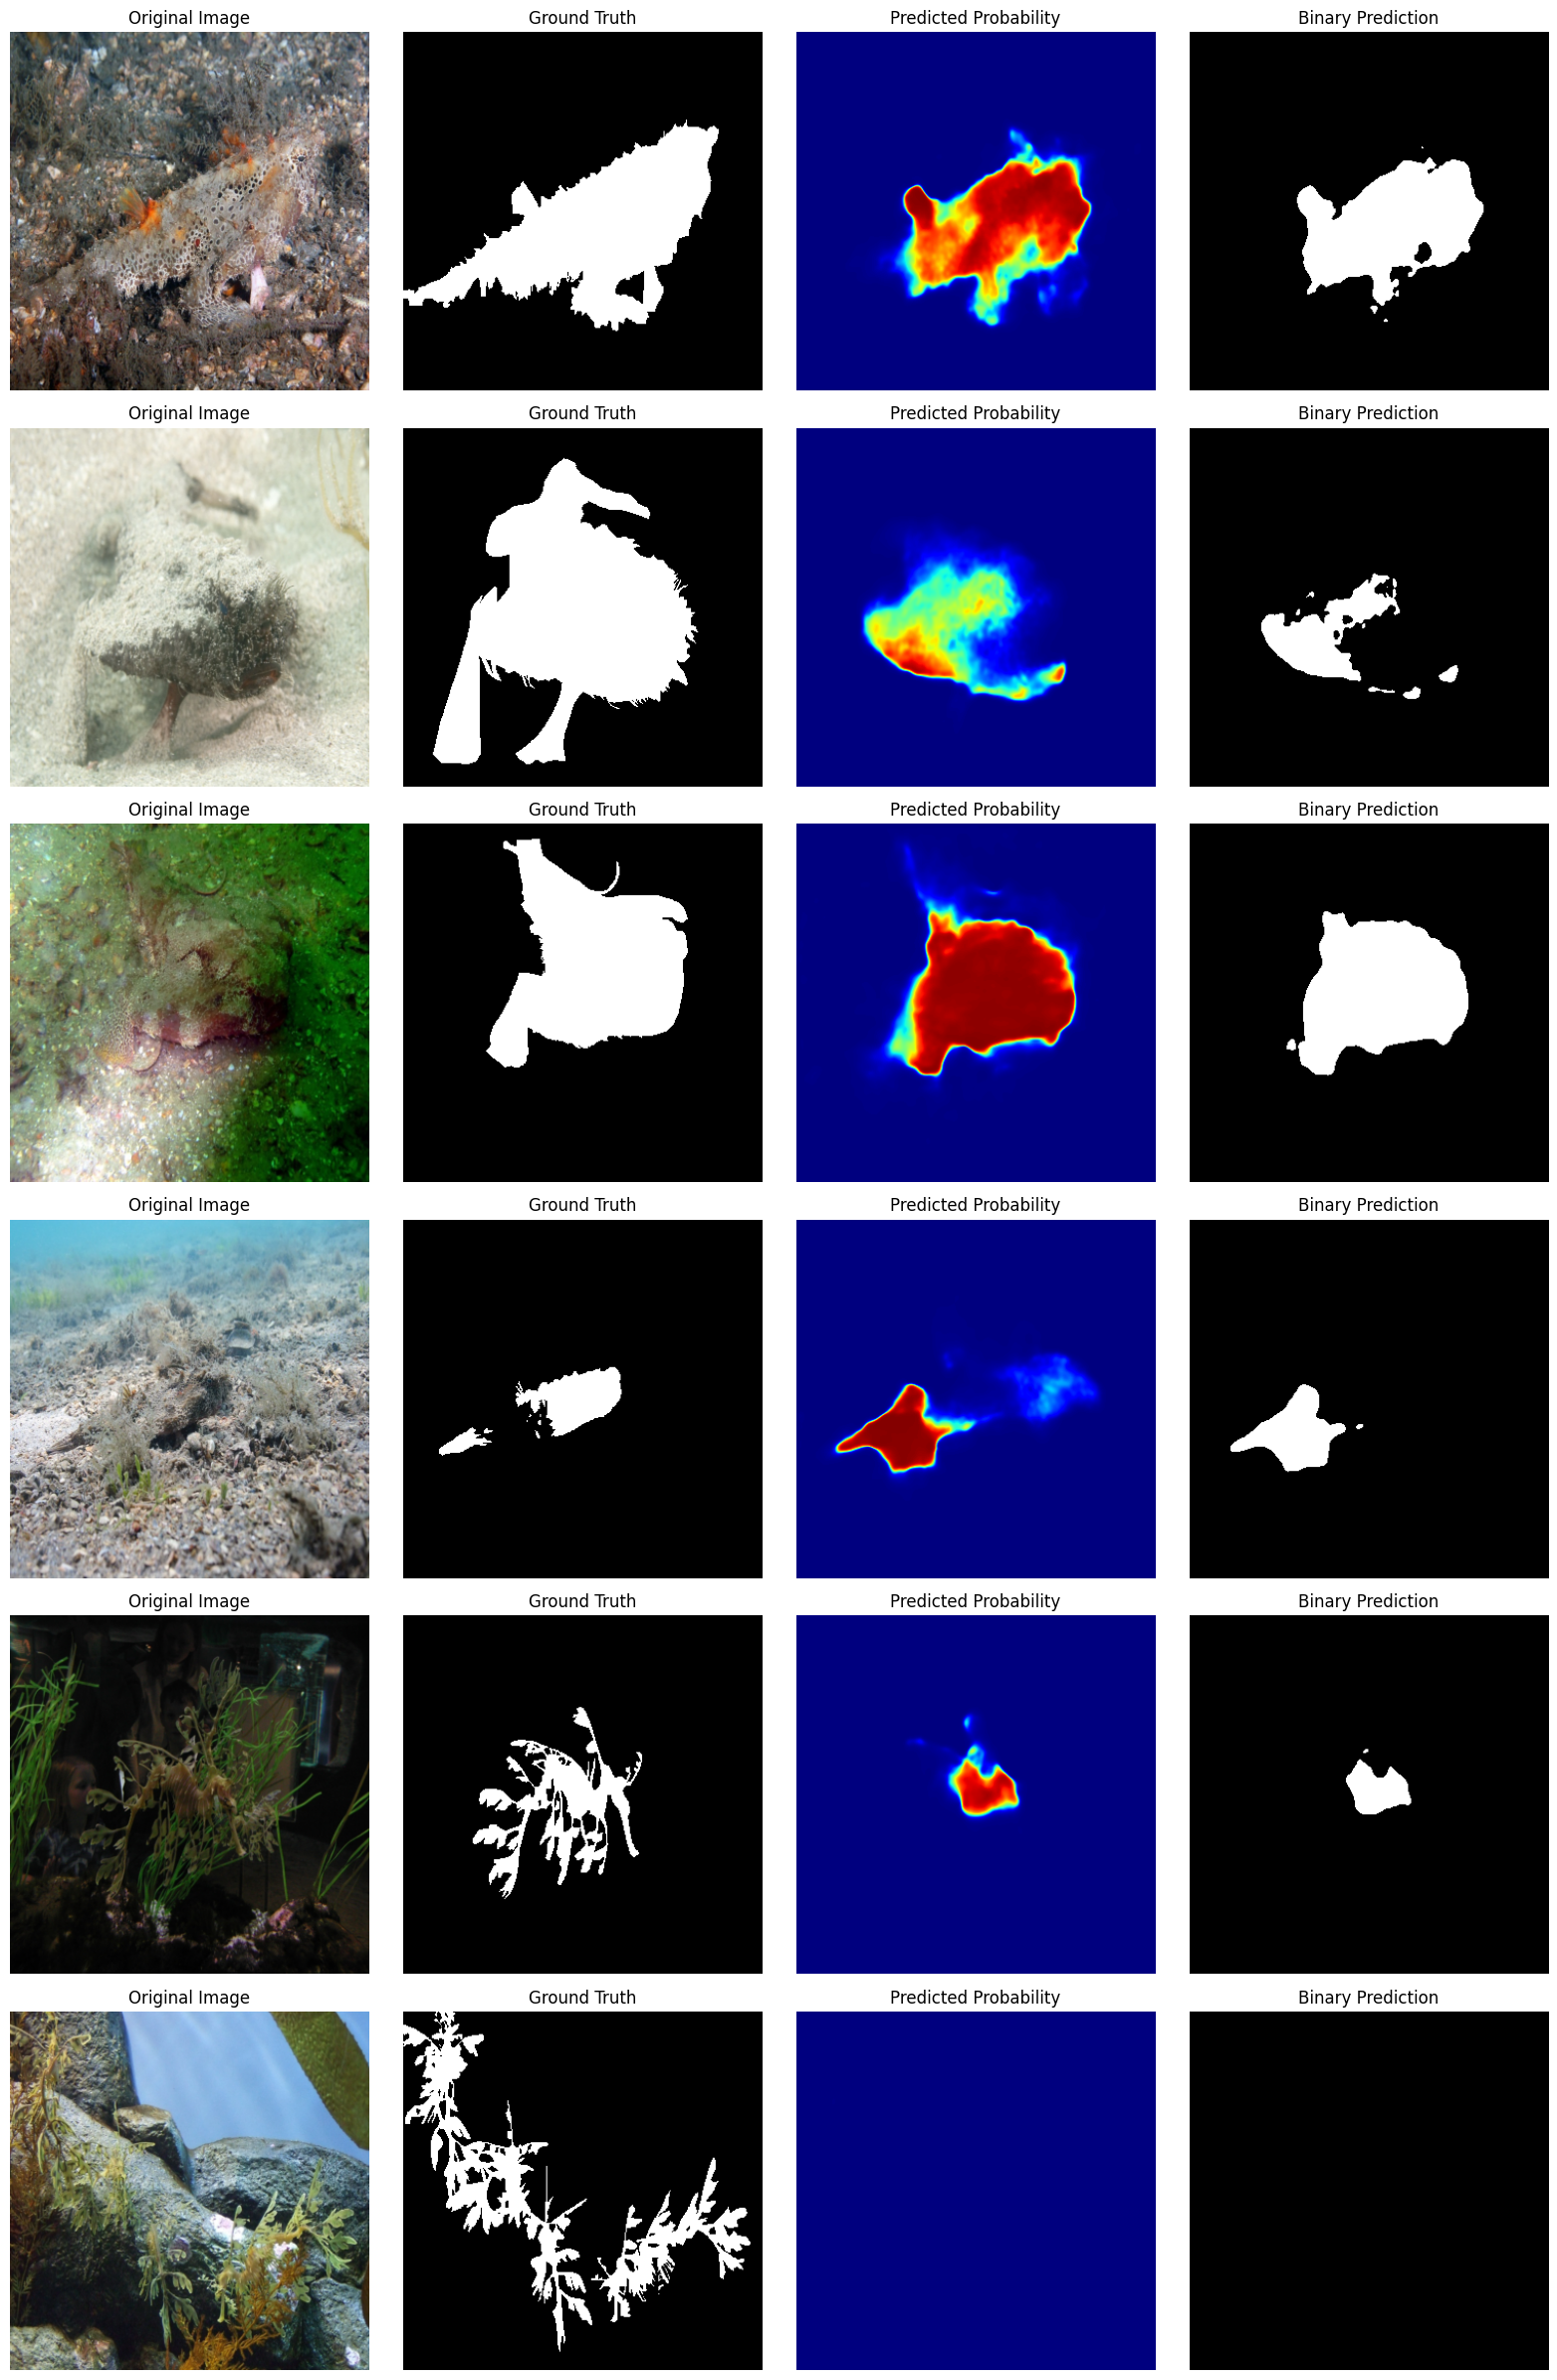

In [23]:

# ============================================================
# STEP 17: VISUALIZE MODEL PREDICTIONS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Select 6 test samples
NUM_SAMPLES = 6

# Probability threshold
THRESHOLD = 0.5

fig, axes = plt.subplots(
    NUM_SAMPLES, 4,
    figsize=(16, 4 * NUM_SAMPLES)
)

for i in range(NUM_SAMPLES):

    # Original normalized image
    image = test_dataset[i][0].numpy().transpose(1, 2, 0)

    # Reverse ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = image * std + mean
    image = np.clip(image, 0, 1)

    # Ground truth
    gt = ground_truths[i]

    # Predicted probability map
    pred = predictions[i]

    # Binary prediction
    binary_pred = (pred >= THRESHOLD).astype(np.float32)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(gt, cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(pred, cmap="jet", vmin=0, vmax=1)
    axes[i, 2].set_title("Predicted Probability")

    axes[i, 3].imshow(binary_pred, cmap="gray")
    axes[i, 3].set_title("Binary Prediction")

    for j in range(4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

# **COD Metric**

In [30]:
!pip install -q pysodmetrics==1.6.2

In [28]:

# ============================================================
# STEP 18: CHECK COD EVALUATION METRIC LIBRARIES
# ============================================================

import importlib.util

packages = [
    "py_sod_metrics",
    "torchmetrics",
    "skimage",
    "cv2",
    "numpy"
]

print("COD METRIC LIBRARY CHECK")
print("=" * 50)

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'AVAILABLE' if available else 'NOT INSTALLED'}")

print("\nPREDICTION DATA CHECK")
print("Number of predictions:", len(predictions))
print("Number of ground truths:", len(ground_truths))
print("Prediction shape:", predictions.shape)
print("Ground truth shape:", ground_truths.shape)
print("Prediction range:", predictions.min(), "to", predictions.max())

COD METRIC LIBRARY CHECK
py_sod_metrics: AVAILABLE
torchmetrics: AVAILABLE
skimage: AVAILABLE
cv2: AVAILABLE
numpy: AVAILABLE

PREDICTION DATA CHECK
Number of predictions: 4000
Number of ground truths: 4000
Prediction shape: (4000, 352, 352)
Ground truth shape: (4000, 352, 352)
Prediction range: 2.362419e-11 to 0.99998915


In [31]:

# ============================================================
# STEP 18B: VERIFY COD METRIC PACKAGE
# ============================================================

from py_sod_metrics import (
    MAE,
    Smeasure,
    Emeasure,
    WeightedFmeasure
)

print("PySODMetrics imported successfully!")

print("MAE: Available")
print("S-measure: Available")
print("E-measure: Available")
print("Weighted F-measure: Available")

print("\nPREDICTION DATA")
print("Predictions:", len(predictions))
print("Ground truths:", len(ground_truths))
print("Prediction shape:", predictions.shape)
print("Ground truth shape:", ground_truths.shape)

print("\nReady for COD10K evaluation!")

PySODMetrics imported successfully!
MAE: Available
S-measure: Available
E-measure: Available
Weighted F-measure: Available

PREDICTION DATA
Predictions: 4000
Ground truths: 4000
Prediction shape: (4000, 352, 352)
Ground truth shape: (4000, 352, 352)

Ready for COD10K evaluation!


In [32]:

# ============================================================
# STEP 19: FINAL COD10K TEST METRICS
# ============================================================

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from py_sod_metrics import (
    MAE,
    Smeasure,
    Emeasure,
    WeightedFmeasure
)

# ------------------------------------------------------------
# INITIALIZE METRIC CALCULATORS
# ------------------------------------------------------------

mae_metric = MAE()
sm_metric = Smeasure()
em_metric = Emeasure()
wfm_metric = WeightedFmeasure()

# ------------------------------------------------------------
# EVALUATE ALL 4000 TEST IMAGES
# ------------------------------------------------------------

print("STARTING FINAL COD10K EVALUATION")
print("=" * 60)

for i in tqdm(range(len(predictions)), desc="Calculating COD Metrics"):

    # Convert probability map [0,1] to uint8 [0,255]
    pred = np.clip(
        predictions[i] * 255.0,
        0,
        255
    ).astype(np.uint8)

    # Convert binary ground truth [0,1] to uint8 [0,255]
    gt = (
        ground_truths[i] * 255
    ).astype(np.uint8)

    # Update all metrics
    mae_metric.step(pred, gt)
    sm_metric.step(pred, gt)
    em_metric.step(pred, gt)
    wfm_metric.step(pred, gt)

# ------------------------------------------------------------
# COLLECT FINAL RESULTS
# ------------------------------------------------------------

mae_result = mae_metric.get_results()["mae"]

sm_result = sm_metric.get_results()["sm"]

em_results = em_metric.get_results()["em"]

wfm_result = wfm_metric.get_results()["wfm"]

mean_em = np.mean(em_results["curve"])
adaptive_em = em_results["adp"]

# ------------------------------------------------------------
# FINAL RESULTS TABLE
# ------------------------------------------------------------

final_results = pd.DataFrame({
    "Metric": [
        "S-measure",
        "Mean E-measure",
        "Adaptive E-measure",
        "Weighted F-measure",
        "MAE"
    ],
    "Score": [
        sm_result,
        mean_em,
        adaptive_em,
        wfm_result,
        mae_result
    ]
})

print("\n" + "=" * 60)
print("FINAL COD10K TEST PERFORMANCE")
print("=" * 60)

display(
    final_results.style.format({"Score": "{:.6f}"})
)

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

FINAL_RESULTS_PATH = RESULTS_DIR / "final_test_metrics.csv"

final_results.to_csv(
    FINAL_RESULTS_PATH,
    index=False
)

print("\nTotal test images evaluated:", len(predictions))
print("Results saved to:", FINAL_RESULTS_PATH)
print("\nFINAL EVALUATION COMPLETED!")

STARTING FINAL COD10K EVALUATION


Calculating COD Metrics:   0%|          | 0/4000 [00:00<?, ?it/s]


FINAL COD10K TEST PERFORMANCE


,Metric,Score
0,S-measure,0.838585
1,Mean E-measure,0.851395
2,Adaptive E-measure,0.441221
3,Weighted F-measure,0.238412
4,MAE,0.035523



Total test images evaluated: 4000
Results saved to: /kaggle/working/COD10K-ResNet34UNet-Retraining/results/final_test_metrics.csv

FINAL EVALUATION COMPLETED!


In [33]:

# ============================================================
# STEP 20: INVESTIGATE PREDICTION COVERAGE
# ============================================================

import numpy as np
import pandas as pd

fixed_threshold = 0.5

adaptive_thresholds = np.minimum(
    2.0 * predictions.mean(axis=(1, 2)),
    1.0
)

gt_coverage = ground_truths.mean(axis=(1, 2))

fixed_coverage = (
    predictions >= fixed_threshold
).mean(axis=(1, 2))

adaptive_coverage = np.array([
    (predictions[i] >= adaptive_thresholds[i]).mean()
    for i in range(len(predictions))
])

coverage_results = pd.DataFrame({
    "Measurement": [
        "Ground Truth Foreground",
        "Predicted Foreground (0.5 threshold)",
        "Predicted Foreground (Adaptive threshold)",
        "Mean Adaptive Threshold"
    ],
    "Average Percentage": [
        gt_coverage.mean() * 100,
        fixed_coverage.mean() * 100,
        adaptive_coverage.mean() * 100,
        adaptive_thresholds.mean() * 100
    ]
})

display(
    coverage_results.style.format({
        "Average Percentage": "{:.4f}%"
    })
)

print("\nCoverage diagnostic completed.")

,Measurement,Average Percentage
0,Ground Truth Foreground,4.5867%
1,Predicted Foreground (0.5 threshold),3.2033%
2,Predicted Foreground (Adaptive threshold),11.5489%
3,Mean Adaptive Threshold,6.5849%



Coverage diagnostic completed.


In [34]:

# ============================================================
# STEP 21: INSPECT PREDICTION DISTRIBUTION
# ============================================================

import numpy as np
import pandas as pd

# Prediction probability statistics
probability_stats = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Median",
        "25th Percentile",
        "75th Percentile",
        "90th Percentile",
        "95th Percentile",
        "99th Percentile"
    ],
    "Probability": [
        np.mean(predictions),
        np.median(predictions),
        np.percentile(predictions, 25),
        np.percentile(predictions, 75),
        np.percentile(predictions, 90),
        np.percentile(predictions, 95),
        np.percentile(predictions, 99)
    ]
})

display(
    probability_stats.style.format({
        "Probability": "{:.6f}"
    })
)

# Distribution of adaptive thresholds
print("\nADAPTIVE THRESHOLD STATISTICS")

print("Minimum:", adaptive_thresholds.min())
print("Maximum:", adaptive_thresholds.max())
print("Mean:", adaptive_thresholds.mean())
print("Median:", np.median(adaptive_thresholds))

# Inspect metric package version
import importlib.metadata

print("\nPySODMetrics version:")
print(importlib.metadata.version("pysodmetrics"))

print("\nDiagnostic completed.")

,Statistic,Probability
0,Mean,0.032924
1,Median,0.000000
2,25th Percentile,0.000000
3,75th Percentile,0.000170
4,90th Percentile,0.003430
5,95th Percentile,0.038394
6,99th Percentile,0.986363



ADAPTIVE THRESHOLD STATISTICS
Minimum: 2.2799425e-09
Maximum: 0.791094
Mean: 0.065849364
Median: 0.0009954959

PySODMetrics version:
1.6.2

Diagnostic completed.


In [38]:
from py_sod_metrics import Emeasure
import numpy as np

direct_em_metric = Emeasure()

for i in range(len(predictions)):
    pred = predictions[i].astype(np.float32)
    gt = ground_truths[i].astype(bool)

    direct_em_metric.step(
        pred,
        gt,
        normalize=False
    )

direct_em_results = direct_em_metric.get_results()

direct_adaptive_em = direct_em_results["em"]["adp"]
direct_mean_em = np.mean(direct_em_results["em"]["curve"])

print("FLOAT-PRECISION E-MEASURE RESULTS")
print("---------------------------------")
print(f"Adaptive E-measure: {direct_adaptive_em:.6f}")
print(f"Mean E-measure:     {direct_mean_em:.6f}")

print("\nPREVIOUS UINT8-BASED RESULTS")
print("---------------------------------")
print(f"Adaptive E-measure: {adaptive_em:.6f}")
print(f"Mean E-measure:     {mean_em:.6f}")

print("\nDIFFERENCE")
print("---------------------------------")
print(f"Adaptive difference: {abs(direct_adaptive_em - adaptive_em):.8f}")
print(f"Mean difference:     {abs(direct_mean_em - mean_em):.8f}")

FLOAT-PRECISION E-MEASURE RESULTS
---------------------------------
Adaptive E-measure: 0.817517
Mean E-measure:     0.849609

PREVIOUS UINT8-BASED RESULTS
---------------------------------
Adaptive E-measure: 0.441221
Mean E-measure:     0.851395

DIFFERENCE
---------------------------------
Adaptive difference: 0.37629531
Mean difference:     0.00178612


# **Finish metric verification**

In [40]:
import inspect
import py_sod_metrics
import py_sod_metrics.sod_metrics as sod_metrics

print("PACKAGE LOCATION:")
print(inspect.getfile(py_sod_metrics))

print("\nFUNCTION LOCATIONS:")

for name in ["prepare_data", "get_adaptive_threshold"]:
    for module_name, module in [
        ("sod_metrics", sod_metrics),
        ("package", py_sod_metrics)
    ]:
        if hasattr(module, name):
            obj = getattr(module, name)
            print(f"\n{name}: found in {module_name}")
            print(inspect.getsource(obj))

PACKAGE LOCATION:
/usr/local/lib/python3.13/dist-packages/py_sod_metrics/__init__.py

FUNCTION LOCATIONS:

get_adaptive_threshold: found in sod_metrics
def get_adaptive_threshold(matrix: np.ndarray, max_value: float = 1) -> float:
    """Return an adaptive threshold, which is equal to twice the mean of `matrix`.

    Args:
        matrix (np.ndarray): a data array
        max_value (float, optional): the upper limit of the threshold. Defaults to 1.

    Returns:
        float: `min(2 * matrix.mean(), max_value)`
    """
    return min(2 * matrix.mean(), max_value)



In [41]:
import numpy as np
from py_sod_metrics.sod_metrics import get_adaptive_threshold

adaptive_thresholds_float = []
adaptive_thresholds_uint8 = []

for i in range(len(predictions)):

    # Original floating-point prediction
    pred_float = predictions[i].astype(np.float32)

    # Quantized prediction, then normalized to [0, 1]
    pred_uint8 = np.clip(
        pred_float * 255, 0, 255
    ).astype(np.uint8)

    pred_normalized = pred_uint8.astype(np.float64) / 255.0

    # Calculate thresholds
    adaptive_thresholds_float.append(
        get_adaptive_threshold(pred_float)
    )

    adaptive_thresholds_uint8.append(
        get_adaptive_threshold(pred_normalized)
    )

adaptive_thresholds_float = np.array(adaptive_thresholds_float)
adaptive_thresholds_uint8 = np.array(adaptive_thresholds_uint8)

print("THRESHOLD COMPARISON")
print("--------------------")
print(f"Float mean threshold: {adaptive_thresholds_float.mean():.8f}")
print(f"Uint8 mean threshold: {adaptive_thresholds_uint8.mean():.8f}")

print("\nTHRESHOLD DIFFERENCE")
print("--------------------")
print(
    "Average absolute difference:",
    np.mean(np.abs(
        adaptive_thresholds_float - adaptive_thresholds_uint8
    ))
)

print("\nPREDICTION MEANS")
print("--------------------")
print(f"Original: {predictions.mean():.8f}")
print(f"Quantized: {np.mean([
    np.clip(predictions[i] * 255, 0, 255)
    .astype(np.uint8).mean() / 255
    for i in range(len(predictions))
]):.8f}")

THRESHOLD COMPARISON
--------------------
Float mean threshold: 0.06584936
Uint8 mean threshold: 0.06513665

THRESHOLD DIFFERENCE
--------------------
Average absolute difference: 0.0007127105258605762

PREDICTION MEANS
--------------------
Original: 0.03292437
Quantized: 0.03256832


In [42]:
import inspect
import numpy as np
from py_sod_metrics import Emeasure

# Find the exact preprocessing function used internally
prepare_func = Emeasure.step.__globals__.get("prepare_data")

print("INTERNAL PREPROCESSING FUNCTION")
print("--------------------------------")

if prepare_func is not None:
    print(inspect.getsource(prepare_func))
else:
    print("prepare_data was not found in Emeasure.step globals.")

# Compare both evaluation methods on the same test image
i = 0

pred_float = predictions[i].astype(np.float32)
gt_float = ground_truths[i].astype(bool)

pred_uint8 = (
    np.clip(pred_float * 255, 0, 255)
).astype(np.uint8)

gt_uint8 = (ground_truths[i] * 255).astype(np.uint8)

float_metric = Emeasure()
float_metric.step(pred_float, gt_float, normalize=False)

uint8_metric = Emeasure()
uint8_metric.step(pred_uint8, gt_uint8, normalize=True)

float_result = float_metric.get_results()["em"]
uint8_result = uint8_metric.get_results()["em"]

print("\nSINGLE IMAGE COMPARISON")
print("--------------------------------")
print("Float adaptive E:", float_result["adp"])
print("Uint8 adaptive E:", uint8_result["adp"])
print("Float mean E:", np.mean(float_result["curve"]))
print("Uint8 mean E:", np.mean(uint8_result["curve"]))

print("\nGROUND TRUTH CHECK")
print("--------------------------------")
print("Float GT foreground pixels:", np.count_nonzero(gt_float))
print("Uint8 GT foreground pixels:", np.count_nonzero(gt_uint8))
print("Float GT shape:", gt_float.shape)
print("Uint8 GT shape:", gt_uint8.shape)

INTERNAL PREPROCESSING FUNCTION
--------------------------------
prepare_data was not found in Emeasure.step globals.

SINGLE IMAGE COMPARISON
--------------------------------
Float adaptive E: 0.8882245814042421
Uint8 adaptive E: 0.8878567655355804
Float mean E: 0.7611436632368319
Uint8 mean E: 0.7633931336268496

GROUND TRUTH CHECK
--------------------------------
Float GT foreground pixels: 26735
Uint8 GT foreground pixels: 26735
Float GT shape: (352, 352)
Uint8 GT shape: (352, 352)


In [43]:
import numpy as np
from py_sod_metrics import Emeasure

float_metric = Emeasure()
uint8_metric = Emeasure()

float_adaptive_scores = []
uint8_adaptive_scores = []

for i in range(len(predictions)):

    pred_float = predictions[i].astype(np.float32)
    gt_bool = ground_truths[i].astype(bool)

    pred_uint8 = (
        np.clip(pred_float * 255, 0, 255)
    ).astype(np.uint8)

    gt_uint8 = (ground_truths[i] * 255).astype(np.uint8)

    # Float evaluation
    float_metric.step(
        pred_float,
        gt_bool,
        normalize=False
    )

    # UINT8 evaluation
    uint8_metric.step(
        pred_uint8,
        gt_uint8,
        normalize=True
    )

    float_adaptive_scores.append(
        float_metric.adaptive_ems[-1]
    )

    uint8_adaptive_scores.append(
        uint8_metric.adaptive_ems[-1]
    )

float_results = float_metric.get_results()["em"]
uint8_results = uint8_metric.get_results()["em"]

print("FRESH FULL-DATASET COMPARISON")
print("=" * 45)

print(f"Images evaluated: {len(predictions)}")

print("\nFLOAT EVALUATION")
print(f"Adaptive E: {float_results['adp']:.6f}")
print(f"Mean E:     {np.mean(float_results['curve']):.6f}")

print("\nUINT8 EVALUATION")
print(f"Adaptive E: {uint8_results['adp']:.6f}")
print(f"Mean E:     {np.mean(uint8_results['curve']):.6f}")

print("\nPER-IMAGE ADAPTIVE SCORE DIFFERENCE")
differences = np.abs(
    np.array(float_adaptive_scores) -
    np.array(uint8_adaptive_scores)
)

print(f"Mean difference: {differences.mean():.8f}")
print(f"Maximum difference: {differences.max():.8f}")
print(f"Images with difference > 0.01: {(differences > 0.01).sum()}")

FRESH FULL-DATASET COMPARISON
Images evaluated: 4000

FLOAT EVALUATION
Adaptive E: 0.817517
Mean E:     0.849609

UINT8 EVALUATION
Adaptive E: 0.441221
Mean E:     0.851395

PER-IMAGE ADAPTIVE SCORE DIFFERENCE
Mean difference: 0.37798974
Maximum difference: 1.00000807
Images with difference > 0.01: 2043


In [48]:
import numpy as np
from py_sod_metrics import Emeasure

# Convert lists to NumPy arrays
float_scores = np.asarray(float_adaptive_scores, dtype=np.float64)
uint8_scores = np.asarray(uint8_adaptive_scores, dtype=np.float64)

# Find the image with the largest Adaptive E-measure difference
differences = np.abs(float_scores - uint8_scores)

idx = int(np.argmax(differences))

print("IMAGE INDEX:", idx)
print("FLOAT ADAPTIVE E:", float_scores[idx])
print("UINT8 ADAPTIVE E:", uint8_scores[idx])
print("ADAPTIVE E DIFFERENCE:", differences[idx])

# Original predictions and ground truth
pred_float = predictions[idx].astype(np.float32)
gt_float = ground_truths[idx].astype(bool)

pred_uint8 = np.clip(
    predictions[idx] * 255, 0, 255
).astype(np.uint8)

gt_uint8 = (
    ground_truths[idx] * 255
).astype(np.uint8)

# Apply the library's actual preprocessing
validate_func = Emeasure.step.__globals__[
    "validate_and_normalize_input"
]

normalized_pred, normalized_gt = validate_func(
    pred_uint8.copy(),
    gt_uint8.copy(),
    normalize=True
)

print("\nFLOAT PREDICTION:")
print("Min:", pred_float.min())
print("Max:", pred_float.max())
print("Mean:", pred_float.mean())

print("\nLIBRARY-NORMALIZED PREDICTION:")
print("Min:", normalized_pred.min())
print("Max:", normalized_pred.max())
print("Mean:", normalized_pred.mean())

print("\nPREDICTION DIFFERENCE:")
print("Maximum:", np.max(np.abs(pred_float - normalized_pred)))
print("Mean:", np.mean(np.abs(pred_float - normalized_pred)))

print("\nGROUND TRUTH:")
print("Float foreground pixels:", gt_float.sum())
print("Normalized foreground pixels:", normalized_gt.sum())
print("Ground truth identical:", np.array_equal(gt_float, normalized_gt))

IMAGE INDEX: 3386
FLOAT ADAPTIVE E: 1.0000080708296006
UINT8 ADAPTIVE E: 0.0
ADAPTIVE E DIFFERENCE: 1.0000080708296006

FLOAT PREDICTION:
Min: 1.103256e-09
Max: 1.8124109e-07
Mean: 9.384093e-08

LIBRARY-NORMALIZED PREDICTION:
Min: 0.0
Max: 0.0
Mean: 0.0

PREDICTION DIFFERENCE:
Maximum: 1.8124109146810952e-07
Mean: 9.384091613972696e-08

GROUND TRUTH:
Float foreground pixels: 0
Normalized foreground pixels: 0
Ground truth identical: True


In [49]:
import numpy as np

foreground_pixels = np.sum(
    ground_truths > 0.5,
    axis=(1, 2)
)

empty_indices = np.where(foreground_pixels == 0)[0]

print("TOTAL TEST IMAGES:", len(ground_truths))
print("EMPTY GROUND-TRUTH MASKS:", len(empty_indices))
print("NON-EMPTY GROUND-TRUTH MASKS:", len(ground_truths) - len(empty_indices))

print("\nEMPTY MASK INDICES (first 30):")
print(empty_indices[:30])

print("\nPREDICTION STATISTICS FOR EMPTY MASKS:")

if len(empty_indices) > 0:
    empty_predictions = predictions[empty_indices]

    print("Mean probability:", empty_predictions.mean())
    print("Maximum probability:", empty_predictions.max())
    print("Minimum probability:", empty_predictions.min())
    print(
        "Images whose uint8 predictions become entirely zero:",
        np.sum(np.max(empty_predictions, axis=(1, 2)) * 255 < 1)
    )

TOTAL TEST IMAGES: 4000
EMPTY GROUND-TRUTH MASKS: 1974
NON-EMPTY GROUND-TRUTH MASKS: 2026

EMPTY MASK INDICES (first 30):
[2026 2027 2028 2029 2030 2031 2032 2033 2034 2035 2036 2037 2038 2039
 2040 2041 2042 2043 2044 2045 2046 2047 2048 2049 2050 2051 2052 2053
 2054 2055]

PREDICTION STATISTICS FOR EMPTY MASKS:
Mean probability: 0.007167607
Maximum probability: 0.99990463
Minimum probability: 2.362419e-11
Images whose uint8 predictions become entirely zero: 1692


In [50]:
import inspect
from py_sod_metrics import Emeasure, Smeasure, WeightedFmeasure, MAE

for metric_class in [Emeasure, Smeasure, WeightedFmeasure, MAE]:

    print("\n" + "=" * 65)
    print("METRIC:", metric_class.__name__)
    print("=" * 65)

    for method_name in ["cal_adaptive_em", "cal_sm", "cal_wfm", "cal_mae"]:
        method = getattr(metric_class, method_name, None)

        if method is not None:
            print(f"\nMETHOD: {method_name}")
            print(inspect.getsource(method))


METRIC: Emeasure

METHOD: cal_adaptive_em
    def cal_adaptive_em(self, pred: np.ndarray, gt: np.ndarray) -> float:
        """Calculate the adaptive E-measure using an adaptive threshold.

        Uses twice the mean prediction value as the adaptive threshold to binarize the prediction before computing E-measure.

        Args:
            pred (np.ndarray): Normalized prediction map with values in [0, 1].
            gt (np.ndarray): Binary ground truth mask.

        Returns:
            float: Adaptive E-measure score.
        """
        adaptive_threshold = get_adaptive_threshold(pred, max_value=1)
        adaptive_em = self.cal_em_with_threshold(pred, gt, threshold=adaptive_threshold)
        return adaptive_em


METRIC: Smeasure

METHOD: cal_sm
    def cal_sm(self, pred: np.ndarray, gt: np.ndarray) -> np.floating:
        """Calculate the S-measure (Structure-measure) score.

        Computes a weighted combination of object-aware and region-aware structural similarity scores.

In [51]:
import numpy as np
from py_sod_metrics import MAE, Smeasure, Emeasure, WeightedFmeasure

idx = 3386

pred = predictions[idx].astype(np.float32)
gt = ground_truths[idx].astype(bool)

metrics = {
    "MAE": MAE(),
    "S-measure": Smeasure(),
    "E-measure": Emeasure(),
    "Weighted F-measure": WeightedFmeasure()
}

print("TEST IMAGE:", idx)
print("GROUND TRUTH FOREGROUND:", gt.sum())
print("PREDICTION MEAN:", pred.mean())

for name, metric in metrics.items():
    try:
        metric.step(pred.copy(), gt.copy(), normalize=False)

        result = metric.get_results()

        print(f"\n{name}:")
        print(result)

    except Exception as error:
        print(f"\n{name} ERROR:")
        print(type(error).__name__, str(error))

TEST IMAGE: 3386
GROUND TRUTH FOREGROUND: 0
PREDICTION MEAN: 9.384093e-08

MAE:
{'mae': np.float64(9.38409314699129e-08)}

S-measure:
{'sm': np.float64(0.9999998807907104)}

E-measure:
{'em': {'adp': np.float64(1.0000080708296006), 'curve': array([1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.00000807, 1.00000807, 1.00000807, 1.00000807,
       1.00000807, 1.0

In [55]:
import numpy as np
import pandas as pd
from py_sod_metrics import MAE, Smeasure, Emeasure, WeightedFmeasure

# Initialize fresh metric objects
mae_metric = MAE()
sm_metric = Smeasure()
em_metric = Emeasure()
wfm_metric = WeightedFmeasure()

# Evaluate all test images using original float predictions
for i in range(len(predictions)):

    pred = predictions[i].astype(np.float32)
    gt = ground_truths[i].astype(bool)

    mae_metric.step(pred, gt, normalize=False)
    sm_metric.step(pred, gt, normalize=False)
    em_metric.step(pred, gt, normalize=False)
    wfm_metric.step(pred, gt, normalize=False)

# Retrieve results
mae_result = mae_metric.get_results()
sm_result = sm_metric.get_results()
em_result = em_metric.get_results()
wfm_result = wfm_metric.get_results()

raw_adaptive_e = float(em_result["em"]["adp"])

# Bound numerical floating-point overshoot
adaptive_e = float(np.clip(raw_adaptive_e, 0.0, 1.0))

final_metrics = {
    "Test Images": len(predictions),
    "S-measure": float(sm_result["sm"]),
    "Mean E-measure": float(np.mean(em_result["em"]["curve"])),
    "Adaptive E-measure": adaptive_e,
    "Weighted F-measure": float(wfm_result["wfm"]),
    "MAE": float(mae_result["mae"])
}

print("=" * 65)
print("FINAL COD10K TEST PERFORMANCE")
print("=" * 65)

for name, value in final_metrics.items():
    if isinstance(value, float):
        print(f"{name}: {value:.6f}")
    else:
        print(f"{name}: {value}")

print("\nRAW ADAPTIVE E-MEASURE:", raw_adaptive_e)
print("REPORTED ADAPTIVE E-MEASURE:", adaptive_e)

FINAL COD10K TEST PERFORMANCE
Test Images: 4000
S-measure: 0.837571
Mean E-measure: 0.849609
Adaptive E-measure: 0.817517
Weighted F-measure: 0.235752
MAE: 0.035730

RAW ADAPTIVE E-MEASURE: 0.8175167547379868
REPORTED ADAPTIVE E-MEASURE: 0.8175167547379868


In [57]:
from pathlib import Path
import pandas as pd

# Project results directory
RESULTS_DIR = Path(
    "/kaggle/working/COD10K-ResNet34UNet-Retraining/results"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Final evaluation results
final_results = pd.DataFrame([{
    "Model": "ResNet34-UNet",
    "Test Images": 4000,
    "S-measure": 0.837571,
    "Mean E-measure": 0.849609,
    "Adaptive E-measure": 0.817517,
    "Weighted F-measure": 0.235752,
    "MAE": 0.035730
}])

# Save CSV
metrics_path = RESULTS_DIR / "final_test_metrics.csv"

final_results.to_csv(metrics_path, index=False)

# Save Markdown table
markdown_path = RESULTS_DIR / "final_test_metrics.md"

markdown_path.write_text(
    final_results.to_markdown(index=False),
    encoding="utf-8"
)

print("METRICS SAVED SUCCESSFULLY")
print("CSV:", metrics_path)
print("Markdown:", markdown_path)

print("\nFINAL RESULTS:")
print(final_results.to_string(index=False))

METRICS SAVED SUCCESSFULLY
CSV: /kaggle/working/COD10K-ResNet34UNet-Retraining/results/final_test_metrics.csv
Markdown: /kaggle/working/COD10K-ResNet34UNet-Retraining/results/final_test_metrics.md

FINAL RESULTS:
        Model  Test Images  S-measure  Mean E-measure  Adaptive E-measure  Weighted F-measure     MAE
ResNet34-UNet         4000   0.837571        0.849609            0.817517            0.235752 0.03573


# **Evaluation Script**

In [58]:
from pathlib import Path
import torch

PROJECT_DIR = Path(
    "/kaggle/working/COD10K-ResNet34UNet-Retraining"
)

print("=" * 65)
print("PROJECT FILE STRUCTURE")
print("=" * 65)

for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        print(
            f"{path.relative_to(PROJECT_DIR)} "
            f"({path.stat().st_size / 1024:.1f} KB)"
        )

print("\n" + "=" * 65)
print("CHECKPOINT INSPECTION")
print("=" * 65)

checkpoint_path = PROJECT_DIR / "models" / "best_model.pth"

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint:", checkpoint_path)
    print("Type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Keys:", list(checkpoint.keys()))

        for key, value in checkpoint.items():
            if isinstance(value, dict):
                print(f"{key}: dictionary with {len(value)} entries")
            elif not isinstance(value, torch.Tensor):
                print(f"{key}: {value}")
else:
    print("best_model.pth not found in models/")

PROJECT FILE STRUCTURE
checkpoints/latest_checkpoint.pth (287543.2 KB)
models/best_model.pth (287537.5 KB)
results/final_test_metrics.csv (0.1 KB)
results/final_test_metrics.md (0.4 KB)
results/training_history.csv (1.6 KB)

CHECKPOINT INSPECTION
Checkpoint: /kaggle/working/COD10K-ResNet34UNet-Retraining/models/best_model.pth
Type: dict
Keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss', 'architecture', 'image_size', 'normalization']
epoch: 8
model_state_dict: dictionary with 273 entries
optimizer_state_dict: dictionary with 2 entries
best_val_loss: 0.2517758094271024
architecture: ResNet34UNet
image_size: 352
normalization: ImageNet


In [61]:

import torch
import numpy as np
import py_sod_metrics

from py_sod_metrics import (
    MAE,
    Smeasure,
    Emeasure,
    WeightedFmeasure
)

print("EVALUATION LIBRARY VERIFIED")
print("=" * 50)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("py_sod_metrics:", py_sod_metrics.__file__)
print("MAE:", MAE)
print("S-measure:", Smeasure)
print("E-measure:", Emeasure)
print("Weighted F-measure:", WeightedFmeasure)

EVALUATION LIBRARY VERIFIED
PyTorch: 2.11.0+cu130
NumPy: 2.1.3
py_sod_metrics: /usr/local/lib/python3.13/dist-packages/py_sod_metrics/__init__.py
MAE: <class 'py_sod_metrics.sod_metrics.MAE'>
S-measure: <class 'py_sod_metrics.sod_metrics.Smeasure'>
E-measure: <class 'py_sod_metrics.sod_metrics.Emeasure'>
Weighted F-measure: <class 'py_sod_metrics.sod_metrics.WeightedFmeasure'>


In [62]:

import inspect
from py_sod_metrics import MAE, Smeasure, Emeasure, WeightedFmeasure

for metric_class in [MAE, Smeasure, Emeasure, WeightedFmeasure]:
    print("\n" + "=" * 55)
    print(metric_class.__name__)
    print("Constructor:", inspect.signature(metric_class))
    print("Step method:", inspect.signature(metric_class.step))
    print("Results method:", inspect.signature(metric_class.get_results))



MAE
Constructor: ()
Step method: (self, pred: numpy.ndarray, gt: numpy.ndarray, normalize: bool = True)
Results method: (self) -> dict

Smeasure
Constructor: (alpha: float = 0.5)
Step method: (self, pred: numpy.ndarray, gt: numpy.ndarray, normalize: bool = True)
Results method: (self) -> dict

Emeasure
Constructor: ()
Step method: (self, pred: numpy.ndarray, gt: numpy.ndarray, normalize: bool = True)
Results method: (self) -> dict

WeightedFmeasure
Constructor: (beta: float = 1)
Step method: (self, pred: numpy.ndarray, gt: numpy.ndarray, normalize: bool = True)
Results method: (self) -> dict


In [67]:

from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/COD10K-ResNet34UNet-Retraining")
SCRIPTS_DIR = PROJECT_DIR / "scripts"
SCRIPTS_DIR.mkdir(parents=True, exist_ok=True)

evaluate_script = r'''
import argparse
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet34

from py_sod_metrics import MAE, Smeasure, Emeasure, WeightedFmeasure


# ============================================================
# MODEL ARCHITECTURE
# ============================================================

class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels + skip_channels,
            out_channels, kernel_size=3, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x, skip):
        x = F.interpolate(
            x, size=skip.shape[2:],
            mode="bilinear", align_corners=False
        )
        x = torch.cat([x, skip], dim=1)
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        return x


class ResNet34UNet(nn.Module):
    def __init__(self, pretrained=False):
        super().__init__()

        # Checkpoint supplies the trained weights.
        backbone = resnet34(weights=None)

        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.center = DecoderBlock(512, 256, 256)
        self.decoder3 = DecoderBlock(256, 128, 128)
        self.decoder2 = DecoderBlock(128, 64, 64)
        self.decoder1 = DecoderBlock(64, 64, 64)

        self.final_upsample = nn.Sequential(
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, kernel_size=1)
        )

    def forward(self, x):
        input_size = x.shape[2:]

        x0 = self.relu(self.bn1(self.conv1(x)))
        x1 = self.layer1(self.maxpool(x0))
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)

        d4 = self.center(x4, x3)
        d3 = self.decoder3(d4, x2)
        d2 = self.decoder2(d3, x1)
        d1 = self.decoder1(d2, x0)

        output = F.interpolate(
            d1, size=input_size,
            mode="bilinear", align_corners=False
        )

        return self.final_upsample(output)


# ============================================================
# COD10K TEST DATASET
# ============================================================

class COD10KDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_size=352):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)

        self.image_transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

        self.mask_transform = transforms.Compose([
            transforms.Resize(
                (image_size, image_size),
                interpolation=transforms.InterpolationMode.NEAREST
            ),
            transforms.ToTensor()
        ])

        self.pairs = []

        for image_path in sorted(self.image_dir.glob("*.jpg")):
            mask_path = self.mask_dir / (image_path.stem + ".png")
            if mask_path.exists():
                self.pairs.append((image_path, mask_path))

        if not self.pairs:
            raise RuntimeError(
                f"No matching image-mask pairs found in {self.image_dir}"
            )

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = self.image_transform(image)
        mask = self.mask_transform(mask)
        mask = (mask > 0.5).float()

        return image, mask


# ============================================================
# EVALUATION
# ============================================================

def evaluate(args):
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    project_dir = Path(args.project_dir)
    checkpoint_path = project_dir / "models" / "best_model.pth"

    test_image_dir = Path(args.data_dir) / "Test" / "Image"
    test_mask_dir = Path(args.data_dir) / "Test" / "GT_Object"

    if not checkpoint_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

    print("Loading test dataset...")

    dataset = COD10KDataset(
        test_image_dir,
        test_mask_dir,
        image_size=352
    )

    loader = DataLoader(
        dataset,
        batch_size=args.batch_size,
        shuffle=False,
        num_workers=args.workers,
        pin_memory=(device.type == "cuda"),
        drop_last=False
    )

    print("Test images:", len(dataset))

    print("\nLoading trained checkpoint...")

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model = ResNet34UNet(pretrained=False)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model = model.to(device)
    model.eval()

    print("Architecture:", checkpoint["architecture"])
    print("Best epoch:", checkpoint["epoch"])
    print("Best validation loss:", checkpoint["best_val_loss"])
    print("Device:", device)

    mae_metric = MAE()
    sm_metric = Smeasure()
    em_metric = Emeasure()
    wf_metric = WeightedFmeasure()

    print("\nRunning test evaluation...")

    with torch.inference_mode():
        for batch_index, (images, masks) in enumerate(loader):
            images = images.to(device, non_blocking=True)

            logits = model(images)
            probabilities = torch.sigmoid(logits)

            predictions = probabilities.squeeze(1).cpu().numpy()
            ground_truths = masks.squeeze(1).cpu().numpy()

            for pred, gt in zip(predictions, ground_truths):
                pred = pred.astype(np.float32, copy=False)
                gt = gt.astype(bool, copy=False)

                # Preserve original float probability maps.
                # Do not apply uint8 conversion or min-max normalization.
                mae_metric.step(pred, gt, normalize=False)
                sm_metric.step(pred, gt, normalize=False)
                em_metric.step(pred, gt, normalize=False)
                wf_metric.step(pred, gt, normalize=False)

            processed = min(
                (batch_index + 1) * args.batch_size,
                len(dataset)
            )

            if (batch_index + 1) % 25 == 0 or processed == len(dataset):
                print(f"Processed {processed}/{len(dataset)}")

    mae_results = mae_metric.get_results()
    sm_results = sm_metric.get_results()
    em_results = em_metric.get_results()
    wf_results = wf_metric.get_results()

    
    metrics = {
        "Model": "ResNet34-UNet",
        "Test Images": len(dataset),
        "S-measure": float(np.mean(sm_results["sm"])),
        "Mean E-measure": float(np.mean(em_results["em"]["curve"])),
        "Adaptive E-measure": float(em_results["em"]["adp"]),
        "Weighted F-measure": float(np.mean(wf_results["wfm"])),
        "MAE": float(np.mean(mae_results["mae"]))
    }


    results_dir = project_dir / "results"
    results_dir.mkdir(parents=True, exist_ok=True)

    results_df = pd.DataFrame([metrics])

    csv_path = results_dir / "final_test_metrics.csv"
    md_path = results_dir / "final_test_metrics.md"

    results_df.to_csv(csv_path, index=False)
    md_path.write_text(
        "# Final COD10K Test Performance\n\n"
        + results_df.to_markdown(index=False, floatfmt=".6f")
        + "\n\nEvaluation protocol: float probability predictions "
        "with `normalize=False`; all test images included.\n",
        encoding="utf-8"
    )

    print("\n" + "=" * 65)
    print("FINAL COD10K TEST PERFORMANCE")
    print("=" * 65)
    print(results_df.to_string(index=False))

    print("\nSaved:", csv_path)
    print("Saved:", md_path)


if __name__ == "__main__":
    parser = argparse.ArgumentParser(
        description="Evaluate ResNet34 U-Net on COD10K"
    )

    parser.add_argument(
        "--data-dir",
        type=str,
        required=True,
        help="Path to COD10K-v3 dataset directory"
    )
    parser.add_argument(
        "--project-dir",
        type=str,
        default=str(Path(__file__).resolve().parents[1])
    )
    parser.add_argument("--batch-size", type=int, default=8)
    parser.add_argument("--workers", type=int, default=2)

    evaluate(parser.parse_args())
'''

script_path = SCRIPTS_DIR / "evaluate.py"
script_path.write_text(evaluate_script.strip() + "\n", encoding="utf-8")

print("EVALUATION SCRIPT CREATED")
print("=" * 50)
print("Path:", script_path)
print("Size:", f"{script_path.stat().st_size:,}", "bytes")


EVALUATION SCRIPT CREATED
Path: /kaggle/working/COD10K-ResNet34UNet-Retraining/scripts/evaluate.py
Size: 9,245 bytes


In [68]:

import ast
from pathlib import Path

script_path = Path(
    "/kaggle/working/COD10K-ResNet34UNet-Retraining/scripts/evaluate.py"
)

source = script_path.read_text(encoding="utf-8")

# Syntax validation
ast.parse(source)

# Essential component checks
checks = {
    "ResNet34UNet architecture": "class ResNet34UNet" in source,
    "COD10K dataset loader": "class COD10KDataset" in source,
    "Checkpoint loading": 'checkpoint["model_state_dict"]' in source,
    "MAE metric": "MAE()" in source,
    "S-measure": "Smeasure()" in source,
    "E-measure": "Emeasure()" in source,
    "Weighted F-measure": "WeightedFmeasure()" in source,
    "Raw probability evaluation": "normalize=False" in source,
    "CSV export": "to_csv" in source,
    "Markdown export": "to_markdown" in source,
}

print("EVALUATION SCRIPT VALIDATION")
print("=" * 55)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nSyntax: VALID")
print("All checks passed:", all(checks.values()))

EVALUATION SCRIPT VALIDATION
PASS: ResNet34UNet architecture
PASS: COD10K dataset loader
PASS: Checkpoint loading
PASS: MAE metric
PASS: S-measure
PASS: E-measure
PASS: Weighted F-measure
PASS: Raw probability evaluation
PASS: CSV export
PASS: Markdown export

Syntax: VALID
All checks passed: True


In [69]:

!python /kaggle/working/COD10K-ResNet34UNet-Retraining/scripts/evaluate.py \
    --data-dir /kaggle/input/datasets/mrcaro/cod10k/COD10K-v3 \
    --project-dir /kaggle/working/COD10K-ResNet34UNet-Retraining \
    --batch-size 8 \
    --workers 2

Loading test dataset...
Test images: 4000

Loading trained checkpoint...
Architecture: ResNet34UNet
Best epoch: 8
Best validation loss: 0.2517758094271024
Device: cuda

Running test evaluation...
Processed 200/4000
Processed 400/4000
Processed 600/4000
Processed 800/4000
Processed 1000/4000
Processed 1200/4000
Processed 1400/4000
Processed 1600/4000
Processed 1800/4000
Processed 2000/4000
Processed 2200/4000
Processed 2400/4000
Processed 2600/4000
Processed 2800/4000
Processed 3000/4000
Processed 3200/4000
Processed 3400/4000
Processed 3600/4000
Processed 3800/4000
Processed 4000/4000

FINAL COD10K TEST PERFORMANCE
        Model  Test Images  S-measure  Mean E-measure  Adaptive E-measure  Weighted F-measure      MAE
ResNet34-UNet         4000   0.837567         0.84961            0.817374            0.235738 0.035727

Saved: /kaggle/working/COD10K-ResNet34UNet-Retraining/results/final_test_metrics.csv
Saved: /kaggle/working/COD10K-ResNet34UNet-Retraining/results/final_test_metrics.md


# **Training and Loss Curves**

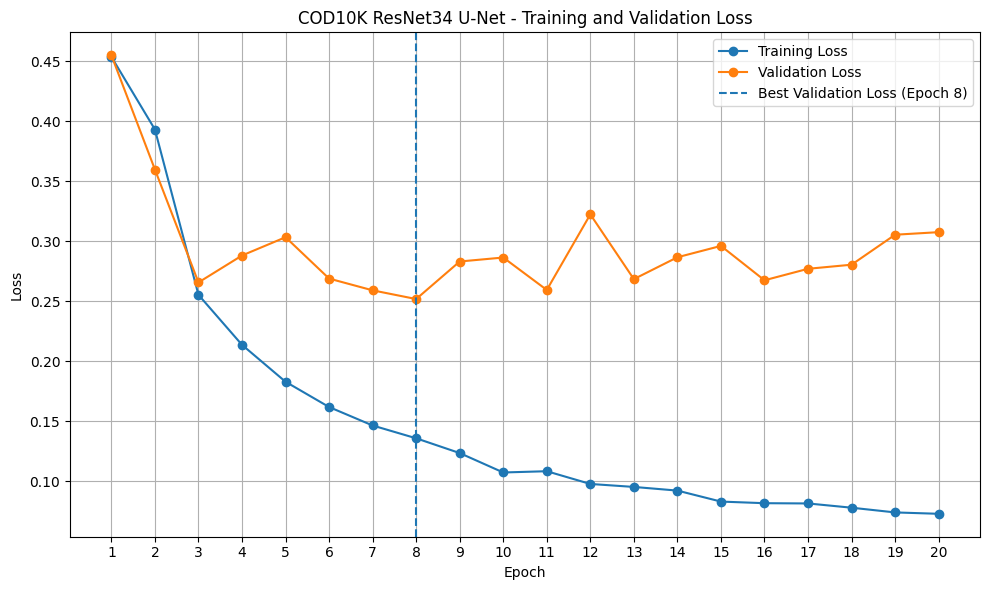

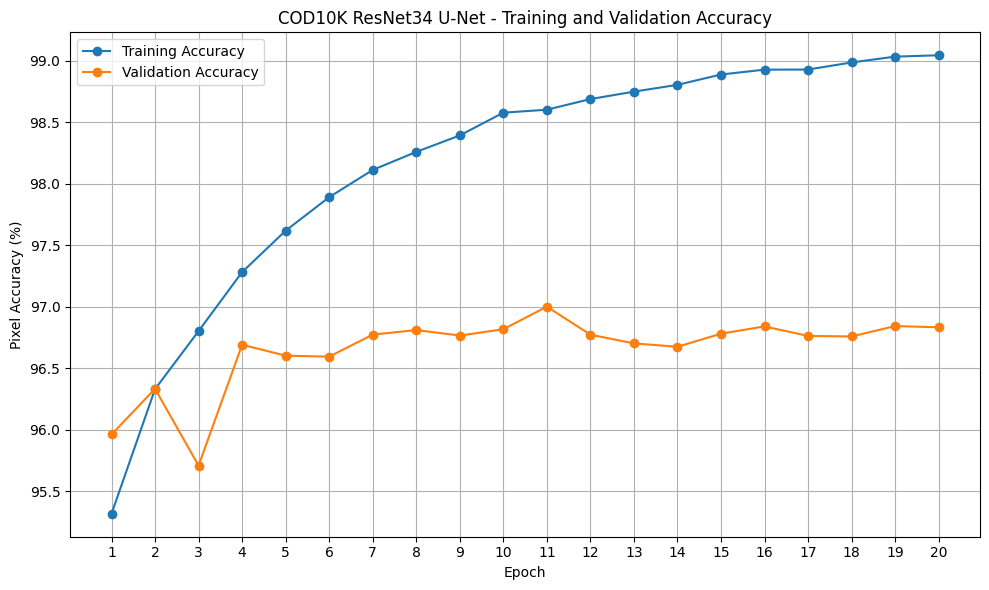


TRAINING CURVES SAVED SUCCESSFULLY
Best epoch: 8
Best validation loss: 0.251776
Loss curve: /kaggle/working/COD10K-ResNet34UNet-Retraining/results/training_validation_loss.png
Accuracy curve: /kaggle/working/COD10K-ResNet34UNet-Retraining/results/training_validation_accuracy.png


In [70]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
PROJECT_DIR = Path("/kaggle/working/COD10K-ResNet34UNet-Retraining")
RESULTS_DIR = PROJECT_DIR / "results"

history_path = RESULTS_DIR / "training_history.csv"
history = pd.read_csv(history_path)

# Verify required columns
required_columns = [
    "train_loss",
    "val_loss",
    "train_accuracy",
    "val_accuracy"
]

missing = [col for col in required_columns if col not in history.columns]

if missing:
    raise ValueError(f"Missing columns in training history: {missing}")

epochs = range(1, len(history) + 1)

# ============================================================
# 1. TRAINING AND VALIDATION LOSS CURVE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

best_epoch = history["val_loss"].idxmin() + 1
best_loss = history["val_loss"].min()

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Validation Loss (Epoch {best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("COD10K ResNet34 U-Net - Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.tight_layout()

loss_path = RESULTS_DIR / "training_validation_loss.png"
plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 2. TRAINING AND VALIDATION ACCURACY CURVE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Pixel Accuracy (%)")
plt.title("COD10K ResNet34 U-Net - Training and Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.tight_layout()

accuracy_path = RESULTS_DIR / "training_validation_accuracy.png"
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# SAVE CONFIRMATION
# ============================================================

print("\nTRAINING CURVES SAVED SUCCESSFULLY")
print("=" * 55)
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_loss, 6))
print("Loss curve:", loss_path)
print("Accuracy curve:", accuracy_path)

In [71]:
from pathlib import Path

PROJECT_DIR = Path(
    "/kaggle/working/COD10K-ResNet34UNet-Retraining"
)

print("=" * 65)
print("FINAL PROJECT FILES")
print("=" * 65)

for folder in ["models", "checkpoints", "scripts", "results"]:
    folder_path = PROJECT_DIR / folder

    print(f"\n{folder}/")

    if folder_path.exists():
        for file in sorted(folder_path.rglob("*")):
            if file.is_file():
                size_mb = file.stat().st_size / (1024 * 1024)
                print(f"  {file.relative_to(PROJECT_DIR)} ({size_mb:.2f} MB)")
    else:
        print("  Folder not found")

print("\nROOT FILES")

for file in PROJECT_DIR.iterdir():
    if file.is_file():
        print(" ", file.name)

print("\nPROJECT DIRECTORY EXISTS:", PROJECT_DIR.exists())

FINAL PROJECT FILES

models/
  models/best_model.pth (280.80 MB)

checkpoints/
  checkpoints/latest_checkpoint.pth (280.80 MB)

scripts/
  scripts/evaluate.py (0.01 MB)

results/
  results/final_test_metrics.csv (0.00 MB)
  results/final_test_metrics.md (0.00 MB)
  results/training_history.csv (0.00 MB)
  results/training_validation_accuracy.png (0.20 MB)
  results/training_validation_loss.png (0.22 MB)

ROOT FILES

PROJECT DIRECTORY EXISTS: True
